Recommends which regions are the best candidates for new charging stations by comparing regional demand, utilisation, and customer reach with the supply of stations and chargers. The data contains no coordinates or population figures, so the analysis works at the regional level (9 regions) and cannot name specific sites. Demand turns out to be almost identical at every station, so the recommendations rest on where supply is thinnest, not on where demand is highest.  
Definitions used throughout:  
* **Region:** one of the 9 regions in the stations table.
* **Demand:** sessions, energy (kWh), and revenue at a region's stations.
* **Supply:** the number of stations, chargers, and installed power (kW) in a region.
* **Gap:** a region's share of network demand minus its share of network supply. A positive gap means the region has less supply than its demand share suggests.
* **Customer reach:** the number of different customers who charged at a region's stations, per station. 
* **Location score:** a weighted score from 0 to 100 that ranks regions as candidates for new stations (highest means a stronger case). 
* **Sensitivity test:** re-ranking the regions many times with random weights to see whether the ranking depends on the weights chosen. 

**Set up**  
Libraries are imported, and the input path is set. show() saves every chart as a PNG in a figures folder (for the repo) and then displays it.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 50, 'axes.titlesize': 12, 'axes.labelsize': 10})

DATA_PATH = '/kaggle/input/datasets/sanyazuberi/ev-charging-raw-dataset/Copy of ev_charging_dataset.xlsx'
OUT = '/kaggle/working'
FIG_DIR = f'{OUT}/figures'
os.makedirs(FIG_DIR, exist_ok=True)

def show(name):
    """Save the current figure as a PNG (for the repo) and display it."""
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=100, bbox_inches='tight')
    plt.show()

**Loading the data**  
All three sheets are used: stations (region, size, and activation year), chargers (rated power), and sessions (demand and customers).

In [2]:
stations = pd.read_excel(DATA_PATH, sheet_name='stations')
chargers = pd.read_excel(DATA_PATH, sheet_name='chargers')
sessions = pd.read_excel(DATA_PATH, sheet_name='sessions')

for c in ['start_timestamp', 'end_timestamp']:
    sessions[c] = pd.to_datetime(sessions[c])

print(f"stations: {len(stations)} | chargers: {len(chargers)} | sessions: {len(sessions):,} | customers: {sessions['customer_id'].nunique():,}")
print(sessions['start_timestamp'].min().date(), 'to', sessions['start_timestamp'].max().date())

stations: 33 | chargers: 199 | sessions: 294,024 | customers: 8,000
2022-01-01 to 2024-12-31


The data has 33 stations, 199 chargers, 294,024 sessions, and 8,000 customers, from 1 January 2022 to 31 December 2024.

**What can this data say about location?**  
Location planning needs to know where things are and how many people live there. The column names were searched for location words, and the regions were counted. The two things that determine how far a regional analysis can go were checked: whether demand differs between stations, and whether customers stay within one region. Demand per station is measured in sessions per day, from 1 January of the station's activation year to the end of 2024.

In [3]:
loc_words = ['lat', 'latitude', 'lon', 'lng', 'longitude', 'postcode', 'address', 'coord', 'coordinates', 'population']
for name, df in [('stations', stations), ('chargers', chargers), ('sessions', sessions)]:
    hits = [c for c in df.columns if any(w in c.lower().split('_') for w in loc_words)]
    print(f"{name}: location-related columns = {hits}")
print('Regions:', stations['region'].nunique(), '| stations per region:', stations['region'].value_counts().to_dict())

END = pd.Timestamp('2025-01-01')    # end of 2024
stn = stations.copy()
stn['avail_days'] = (END - pd.to_datetime(stn['activation_year'].astype(str) + '-01-01')).dt.days
stn = stn.merge(sessions.groupby('station_id').size().rename('sessions'), on='station_id')
stn['sessions_per_day'] = stn['sessions'] / stn['avail_days']

print('Sessions per station per day (mean / std / min / max):', stn['sessions_per_day'].agg(['mean', 'std', 'min', 'max']).round(2).to_dict())
display(stn.groupby('activation_year')['sessions_per_day'].agg(['count', 'mean']).round(2))
display(stn.groupby('n_chargers')['sessions_per_day'].agg(['count', 'mean']).round(2))

regions_per_customer = sessions.groupby('customer_id')['station_region'].nunique()
n_sessions = sessions.groupby('customer_id').size()
print('Regions used per customer, customers with more than 5 sessions (median / mean):',
      regions_per_customer[n_sessions > 5].median(), '/', round(regions_per_customer[n_sessions > 5].mean(), 1))
print('Share of those customers using 5 or more regions:', round((regions_per_customer[n_sessions > 5] >= 5).mean(), 3))

stations: location-related columns = []
chargers: location-related columns = []
sessions: location-related columns = []
Regions: 9 | stations per region: {'North West': 7, 'London': 5, 'Midlands': 5, 'South East': 4, 'South West': 3, 'North East': 3, 'Scotland': 3, 'Yorkshire & Humber': 2, 'Wales': 1}
Sessions per station per day (mean / std / min / max): {'mean': 13.86, 'std': 0.14, 'min': 13.46, 'max': 14.2}


,count,mean
activation_year,,
2022,8,13.85
2023,9,13.90
2024,16,13.85


,count,mean
n_chargers,,
4,9,13.84
5,6,13.97
6,4,13.95
7,3,13.96
8,11,13.77


Regions used per customer, customers with more than 5 sessions (median / mean): 8.0 / 7.8
Share of those customers using 5 or more regions: 0.994


No sheet has coordinates, addresses, postcodes, or population figures. The only information is the region name. The 9 regions have very different numbers of stations: North West 7, London 5, South East 3, North East 3, Scotland 3, Yorkshire & Humber 2, and Wales 1.  
Every station gets almost exactly the same demand: 13.9 sessions a day on average (standard deviation 0.14, range 13.5 to 14.2). It makes no difference whether the station opened in 2022 (13.85), 2023 (13.90), or 2024 (13.85), or whether it has 4 chargers (13.84) or 8 (13.77). A region's total demand therefore simply follows how many stations it has.  
Customers do not belong to a region either. Customers with more than 5 sessions use a median of 8 of the 9 regions, and 99% of them use at least 5. Customer density cannot be measured by where customers live, so it will be measured by how many customers each region's station reaches.


**What this means for the approach**  
Because the data holds no locations and demand is equal at every station, the analysis is set up as follows:
* **Region level only.** The 9 regions are compared. Specific sites cannot be named.
* **2024 is used for the comparison.** It is the first year all 33 stations are open, so every region is measured over the same period.
* **The gap analysis shows relative supply, not unmet demand.** It compares each region's share of demand with its share of chargers and installed power. Because demand follows station numbers, a gap means a region has fewer chargers or less power than its demand share suggests.
* **The location score has three supply-side criteria** (the supply gap, energy per installed kW, and customers per station). Its weights are a judgement call, so the ranking is tested with thousands of random weightings.
* **The map uses approximate region centres** typed in by hand, since the data has no coordinates.
* **Wales has one station,** so any result for Wales rests on a single site.

**Building the regional table for 2024**  
For each region, supply (stations, chargers, installed power) is set beside 2024 demand (sessions, energy, revenue, different customers), and the load results are: sessions per station per day, sessions per charger per day, energy per kW of installed power per day, utilisation, and revenue per station per day. 2024 is used because all 33 stations are open for the whole year, so every region is measured over the same period. Utilisation counts busy time, with overlapping sessions on a charger merged.

In [4]:
# busy minutes with overlapping sessions on the same charger merged
s = sessions.merge(chargers[['charger_id', 'max_power_kW']], on='charger_id')
s = s.sort_values(['charger_id', 'start_timestamp']).reset_index(drop=True)
g = s.groupby('charger_id')
prev_max_end = g['end_timestamp'].transform(lambda x: x.cummax().shift())
eff_start = s['start_timestamp'].where(prev_max_end.isna() | (s['start_timestamp'] >= prev_max_end), prev_max_end)
s['busy_min'] = ((s['end_timestamp'] - eff_start).dt.total_seconds() / 60).clip(lower=0)
s['year'] = s['start_timestamp'].dt.year

stn = stn.merge(chargers.groupby('station_id')['max_power_kW'].sum().rename('installed_kw'), on='station_id')
supply = stn.groupby('region').agg(stations=('station_id', 'size'), chargers=('n_chargers', 'sum'), installed_kw=('installed_kw', 'sum'))

s24 = s[s['year'] == 2024]
demand = s24.groupby('station_region').agg(sessions=('session_id', 'size'), kwh=('energy_kwh', 'sum'), revenue=('total_cost', 'sum'),
                                           customers=('customer_id', 'nunique'), busy_min=('busy_min', 'sum'))
DAYS = 366      # 2024 is a leap year
reg = supply.join(demand)
reg['sessions_per_station_day'] = reg['sessions'] / (reg['stations'] * DAYS)
reg['sessions_per_charger_day'] = reg['sessions'] / (reg['chargers'] * DAYS)
reg['kwh_per_kw_day'] = reg['kwh'] / (reg['installed_kw'] * DAYS)
reg['utilisation_pct'] = reg['busy_min'] / (reg['chargers'] * DAYS * 1440) * 100
reg['revenue_per_station_day'] = reg['revenue'] / (reg['stations'] * DAYS)

display(reg.drop(columns='busy_min').round(2).T)
print(f"Network 2024: {reg['sessions'].sum():,} sessions | revenue {reg['revenue'].sum():,.0f} | utilisation {reg['busy_min'].sum() / (reg['chargers'].sum() * DAYS * 1440) * 100:.1f}%")
display(chargers.merge(stations[['station_id', 'region']], on='station_id').groupby(['region', 'charger_type']).size().unstack().fillna(0).astype(int))

region,London,Midlands,North East,North West,Scotland,South East,South West,Wales,Yorkshire & Humber
stations,5.00,5.00,3.00,7.00,3.00,4.00,3.00,1.00,2.00
chargers,25.00,26.00,17.00,48.00,22.00,26.00,15.00,8.00,12.00
installed_kw,2950.00,4000.00,2300.00,6400.00,2900.00,3000.00,2300.00,400.00,1350.00
sessions,25524.00,25180.00,15344.00,35544.00,15152.00,20055.00,15173.00,5048.00,10232.00
kwh,1113599.50,1285571.70,721819.50,1645815.70,712584.00,884457.70,767494.90,166483.80,449966.50
revenue,655334.04,755464.86,424378.67,967589.97,418952.75,519821.77,450782.26,97856.51,264373.57
customers,5192.00,5167.00,4438.00,5577.00,4469.00,4849.00,4453.00,2581.00,3747.00
sessions_per_station_day,13.95,13.76,13.97,13.87,13.80,13.70,13.82,13.79,13.98
sessions_per_charger_day,2.79,2.65,2.47,2.02,1.88,2.11,2.76,1.72,2.33
kwh_per_kw_day,1.03,0.88,0.86,0.70,0.67,0.81,0.91,1.14,0.91


Network 2024: 167,252 sessions | revenue 4,554,554 | utilisation 5.4%


charger_type,DC_150kW,DC_300kW,DC_50kW
region,,,
London,7,4,14
Midlands,7,8,11
North East,7,3,7
North West,20,8,20
Scotland,8,4,10
South East,7,4,15
South West,8,3,4
Wales,0,0,8
Yorkshire & Humber,5,1,6


In 2024, the network has 33 stations, 199 chargers (25,600 kW), 167,252 sessions, and 4.55 million in revenue, with an average utilisation of 5.4%.  
Supply differs a lot between regions. North West has 7 stations, 44 chargers, and 6,400 kW, while Wales has one station with 8 chargers and 400 kW. Demand per station is the same everywhere (13.7 to 14.0 sessions a day), so what differs is the load on each charger. Sessions per day range from 1.72 in Wales and 1.88 in Scotland to 2.79 in London and 2.76 in the South West. Energy per kW of installed power per day ranges from 0.67 in Scotland and 0.70 in the North West to 1.14 in Wales and 1.03 in London. Utilisation runs from 4.4% in Scotland to 7.1% in London.  
Wales stands out because of its charger mix: its 8 chargers are all 50 kW, and it is the only region with no 150 kW ot 300 kW chargers. Its session delivers 33 kWh on average (44 to 51 kWh elsewhere), so its one station earns the least revenue per (267, against 355 to 412 elsewhere).

**Regional demand heatmaps**  
Three heatmaps show demand by region. The first shows total sessions per year, the second shows sessions per station per day (which removes the effect of how many stations each region has), and the third shows the share of each region's 2024 sessions by hour of day. Blank calls are years in which the region has no station yet.

year,2022,2023,2024
station_region,,,
London,5.1,10.1,25.5
Midlands,10.3,15.1,25.2
North East,5.1,10.0,15.3
North West,15.0,15.2,35.5
Scotland,NaN,5.1,15.2
South East,NaN,5.1,20.1
South West,5.0,10.2,15.2
Wales,NaN,5.1,5.0
Yorkshire & Humber,NaN,10.2,10.2


year,2022,2023,2024
station_region,,,
London,14.06,13.84,13.95
Midlands,14.10,13.81,13.76
North East,14.02,13.67,13.97
North West,13.74,13.88,13.87
Scotland,NaN,13.95,13.80
South East,NaN,14.01,13.70
South West,13.83,13.95,13.82
Wales,NaN,14.00,13.79
Yorkshire & Humber,NaN,14.02,13.98


Busiest hour per region: {'London': 10, 'Midlands': 13, 'North East': 13, 'North West': 12, 'Scotland': 10, 'South East': 10, 'South West': 14, 'Wales': 10, 'Yorkshire & Humber': 12}
Peak-hour share of region sessions (min / max): 8.2 / 8.8
Largest difference between regions in any hour (percentage points): 0.85


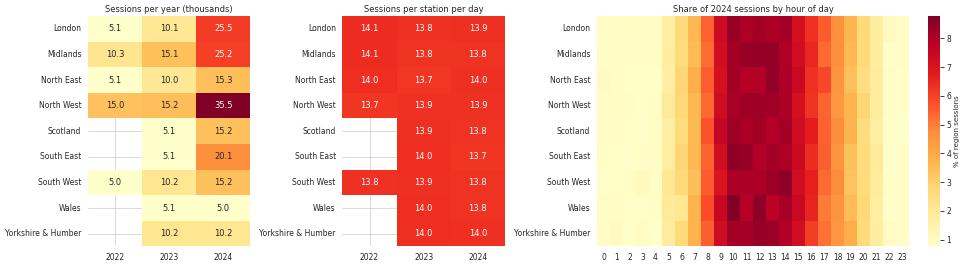

In [5]:
yr = s.groupby(['station_region', 'year']).size().unstack()
days_in_year = {2022: 365, 2023: 365, 2024: 366}
active = pd.DataFrame({y: stations[stations['activation_year'] <= y].groupby('region').size() for y in [2022, 2023, 2024]})
per_station_day = yr / (active * pd.Series(days_in_year))

hour_share = s24.groupby(['station_region', s24['start_timestamp'].dt.hour]).size().unstack()
hour_share = hour_share.div(hour_share.sum(axis=1), axis=0) * 100

display((yr / 1000).round(1))
display(per_station_day.round(2))
print('Busiest hour per region:', hour_share.idxmax(axis=1).to_dict())
print('Peak-hour share of region sessions (min / max):', round(hour_share.max(axis=1).min(), 1), '/', round(hour_share.max(axis=1).max(), 1))
print('Largest difference between regions in any hour (percentage points):', round((hour_share.max() - hour_share.min()).max(), 2))

fig, ax = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={'width_ratios': [1, 1, 2.4]})
sns.heatmap(yr / 1000, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax[0], cbar=False)
ax[0].set_title('Sessions per year (thousands)')
sns.heatmap(per_station_day, annot=True, fmt='.1f', cmap='YlOrRd', vmin=0, vmax=20, ax=ax[1], cbar=False)
ax[1].set_title('Sessions per station per day')
sns.heatmap(hour_share, cmap='YlOrRd', ax=ax[2], cbar_kws={'label': '% of region sessions'})
ax[2].set_title('Share of 2024 sessions by hour of day')
for a in ax:
    a.set_xlabel(''); a.set_ylabel('')
show('01_regional_demand_heatmaps')

Total sessions grow in every region as stations open. For example, North West grew from 15.0 thousand in 2022 to 35.5 thousand in 2024, and London grew from 5.1 thousand to 25.5 thousand. Once the number of stations is taken into account, the pattern disappears: every cell in the sessions-per-station-day heatmap is between 13.7 and 14.1, whatever the region or year. The regions with the most demand are simply the regions with the most stations.  
The hourly pattern is also the same everywhere. Every region peaks between 10:00 and 14:00, with the busiest hour taking 8.2% to 8.8% of the region's sessions, and no region differs from another by more than 0.85 percentage points in any hour. The heatmaps therefore show where demand is largest (North West, London, Midlands), not where it is unusually strong for the number of stations.

**Gap analysis: demand versus supply**  
Each region's share of 2024 network demand (sessions) is compared with its share of stations, chargers, and installed power. The gap is the demand share minus the supply share, in percentage points: positive means the region has less supply than its demand share, negative means more. Because demand follows the number of stations, the gap measures relative supply, not unmet demand.

,demand_share,station_share,charger_share,kw_share,gap_chargers_pp,gap_kw_pp
region,,,,,,
London,15.3,15.2,12.6,11.5,2.7,3.7
Midlands,15.1,15.2,13.1,15.6,2.0,-0.6
South West,9.1,9.1,7.5,9.0,1.5,0.1
North East,9.2,9.1,8.5,9.0,0.6,0.2
Yorkshire & Humber,6.1,6.1,6.0,5.3,0.1,0.8
Wales,3.0,3.0,4.0,1.6,-1.0,1.5
South East,12.0,12.1,13.1,11.7,-1.1,0.3
Scotland,9.1,9.1,11.1,11.3,-2.0,-2.3
North West,21.3,21.2,24.1,25.0,-2.9,-3.7


Correlation between the two gap measures: 0.71


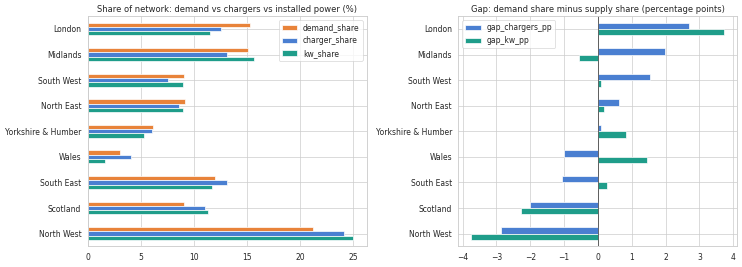

In [6]:
gap = pd.DataFrame({
    'demand_share'  : reg['sessions'] / reg['sessions'].sum() * 100,
    'station_share' : reg['stations'] / reg['stations'].sum() * 100,
    'charger_share' : reg['chargers'] / reg['chargers'].sum() * 100,
    'kw_share'      : reg['installed_kw'] / reg['installed_kw'].sum() * 100})
gap['gap_chargers_pp'] = gap['demand_share'] - gap['charger_share']
gap['gap_kw_pp'] = gap['demand_share'] - gap['kw_share']
gap = gap.sort_values('gap_chargers_pp', ascending=False)
display(gap.round(1))
print('Correlation between the two gap measures:', round(gap['gap_chargers_pp'].corr(gap['gap_kw_pp']), 2))

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
gap[['demand_share', 'charger_share', 'kw_share']].plot(kind='barh', ax=ax[0], color=['#e8833a', '#4a7fd1', '#1f9d8a']).invert_yaxis()
ax[0].set_title('Share of network: demand vs chargers vs installed power (%)'); ax[0].set_ylabel('')
gap[['gap_chargers_pp', 'gap_kw_pp']].plot(kind='barh', ax=ax[1], color=['#4a7fd1', '#1f9d8a']).invert_yaxis()
ax[1].axvline(0, color='black', linewidth=0.8)
ax[1].set_title('Gap: demand share minus supply share (percentage points)'); ax[1].set_ylabel('')
show('02_gap_analysis')

Demand share and station share are almost identical in every region (for example, London 15.3% against 15.2%), which confirms that demand follows station numbers. Gaps appear only because regions differ in chargers per station and power per charger.
London has the largest positive gap: 15.3% of network demand but 12.6% of chargers (+2.7 percentage points) and 11.5% of installed power (+3.7 percentage points). Midlands (+2.0 on chargers), South West (+1.5), and North East (+0.6) also have fewer chargers than their demand share. North West has the most negative gap (-2.9 on chargers, -3.7 on power): 21.3% of demand against 24.1% of chargers and 25.0% of power. Scotland is next at -2.0 and -2.3.
The two measures agree on direction for six of the nine regions (correlation 0.71) but disagree for Midlands (+2.0 on chargers, -0.6 on power), South East (-1.1, +0.3) and Wales (-1.0, +1.5). Wales has enough chargers but little power, since all 8 are 50 kW.
All the gaps are small (at most 3.7 points), and utilisation is low everywhere (4.4% to 7.1%, with London the highest). No region is short of capacity in absolute terms. The gaps show where supply is relatively thinner, which is a weaker case for expansion than a capacity shortage would be.

**Customer reach station**  
Customers use stations  in almost every region, so where a customer lives cannot be found. The closest measure of customer density is reach: the number of different customers who charged at a region's stations in 2024, per station and per charger . A customer is counted in a region however often they charge there. 

,stations,chargers,customers,sessions,customers_per_station,customers_per_charger,share_of_customers_reached,sessions_per_customer
region,,,,,,,,
Wales,1,8,2581,5048,2581.0,322.6,43.0,2.0
Yorkshire & Humber,2,12,3747,10232,1873.5,312.2,62.4,2.7
Scotland,3,22,4469,15152,1489.7,203.1,74.5,3.4
South West,3,15,4453,15173,1484.3,296.9,74.2,3.4
North East,3,17,4438,15344,1479.3,261.1,74.0,3.5
South East,4,26,4849,20055,1212.2,186.5,80.8,4.1
London,5,25,5192,25524,1038.4,207.7,86.5,4.9
Midlands,5,26,5167,25180,1033.4,198.7,86.1,4.9
North West,7,48,5577,35544,796.7,116.2,93.0,6.4


Customers active in 2024: 6000
Correlation between number of stations and customers per station: -0.93


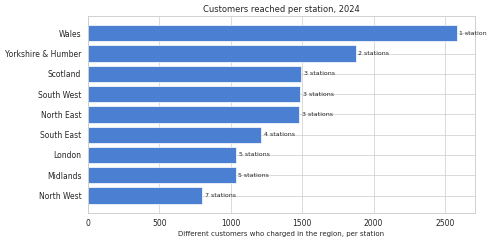

In [7]:
active_customers = s24['customer_id'].nunique()
reach = reg[['stations', 'chargers', 'customers', 'sessions']].copy()
reach['customers_per_station'] = reach['customers'] / reach['stations']
reach['customers_per_charger'] = reach['customers'] / reach['chargers']
reach['share_of_customers_reached'] = reach['customers'] / active_customers * 100
reach['sessions_per_customer'] = reach['sessions'] / reach['customers']
display(reach.sort_values('customers_per_station', ascending=False).round(1))
print('Customers active in 2024:', active_customers)
print('Correlation between number of stations and customers per station:', round(reach['stations'].corr(reach['customers_per_station']), 2))

fig, ax = plt.subplots(figsize=(10, 5))
r = reach.sort_values('customers_per_station')
ax.barh(r.index, r['customers_per_station'], color='#4a7fd1')
for i, (n, v) in enumerate(zip(r['stations'], r['customers_per_station'])):
    ax.text(v + 20, i, f'{n} station' + ('s' if n > 1 else ''), va='center', fontsize=9)
ax.set_title('Customers reached per station, 2024')
ax.set_xlabel('Different customers who charged in the region, per station')
show('03_customer_reach')

6,000 customers were active in 2024. Wales has the most customers per station (2,581, from its single station), followed by Yorkshire & Humber (1,874), Scotland (1,490), South West (1,484), and North East (1,478). North West reaches the fewest per station (797, then Midlands (1,033) and London (1,038).  
This measure is strongly shaped by how many stations a  region has: the correlation between the number of stations and customers per station is -0.93. A customer is counted once, however often they charge, so a region with more stations has more sessions but reaches fewer new customers per extra station. A high value therefore partly reflects having few stations, not crowding. Wales 2,581 comes from one station reaching 43% of the 2024 customer base, against North West's 7 stations reaching 93%.  
It is used in the location score with that in mind, as a measure of how thinly a region's stations are spread across the customer base, with a modest weight.

**Location scoring model**  
Each region is scored on three supply-side criteria, each scaled from 0 (weakest region) to 1 (strongest). The supply ap is the demand share minus the charger share from the gap analysis. Load per installed power is the energy delivered per kW of installed power per day. Customer reach is the number of customers reached per station.  
The score is the weighted sum of the three, from 0 to 100, where higher means a stronger case for a new station. The weights are 40% for the supply gap, 40% for load per installed power, and 20% for customer reach, which gets less weight because it partly reflects how few stations a region has. The weights are a judgment call and are tested in the next chunk. Regions with only one or two stations are marked as lower-confidence.  

,stations,supply_gap,load_per_kw,customer_reach,score,rank,evidence
region,,,,,,,
London,5,2.70,1.03,1038.40,73.6,1,Higher (3+ stations)
Wales,1,-1.00,1.14,2581.00,73.4,2,Low (one station)
South West,3,1.53,0.91,1484.33,60.0,3,Higher (3+ stations)
Midlands,5,1.99,0.88,1033.40,55.3,4,Higher (3+ stations)
Yorkshire & Humber,2,0.09,0.91,1873.50,53.9,5,Medium (two stations)
North East,3,0.63,0.86,1479.33,48.8,6,Higher (3+ stations)
South East,4,-1.07,0.81,1212.25,29.1,7,Higher (3+ stations)
Scotland,3,-2.00,0.67,1489.67,14.0,8,Higher (3+ stations)
North West,7,-2.87,0.70,796.71,2.7,9,Higher (3+ stations)


Correlation between the criteria:


,supply_gap,load_per_kw,customer_reach
supply_gap,1.00,0.54,-0.11
load_per_kw,0.54,1.00,0.59
customer_reach,-0.11,0.59,1.00


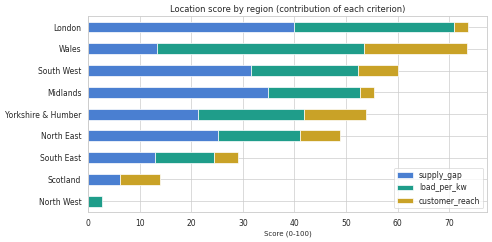

In [8]:
def minmax(x):
    return (x - x.min()) / (x.max() - x.min())

criteria = pd.DataFrame({
    'supply_gap'    : gap['gap_chargers_pp'],
    'load_per_kw'   : reg['kwh_per_kw_day'],
    'customer_reach': reach['customers_per_station']})
norm = criteria.apply(minmax)

WEIGHTS = {'supply_gap': 0.40, 'load_per_kw': 0.40, 'customer_reach': 0.20}
scores = norm.mul(pd.Series(WEIGHTS)).sum(axis=1) * 100

loc = pd.concat([criteria.round(2), norm.round(2).add_suffix('_norm'), scores.round(1).rename('score')], axis=1)
loc['rank'] = loc['score'].rank(ascending=False).astype(int)
loc['stations'] = reg['stations']
loc['evidence'] = np.where(loc['stations'] <= 1, 'Low (one station)',
                  np.where(loc['stations'] == 2, 'Medium (two stations)', 'Higher (3+ stations)'))
loc = loc.sort_values('rank')
display(loc[['stations', 'supply_gap', 'load_per_kw', 'customer_reach', 'score', 'rank', 'evidence']])
print('Correlation between the criteria:')
display(norm.corr().round(2))

fig, ax = plt.subplots(figsize=(10, 5))
parts = (norm.mul(pd.Series(WEIGHTS)) * 100).loc[loc.index[::-1]]
parts.plot(kind='barh', stacked=True, ax=ax, color=['#4a7fd1', '#1f9d8a', '#c9a227'])
ax.set_title('Location score by region (contribution of each criterion)')
ax.set_xlabel('Score (0-100)'); ax.set_ylabel('')
show('04_location_scores')

London ranks first with a score of 73.6, followed by Wales (73.4), the South West (60.0), the Midlands (55.3), Yorkshire & Humber (53.9), the North East (48.8), the South East (29.1), Scotland (14.0), and the North West (2.7). London and Wales are effectively tied.  
London scores highest on the supply gap (+2.7 percentage points) and the second-highest load per kW (1.03). Wales scores through he highest load per kW (1.14) and customer reach (2,581 per station), even though its supply gap is negative (-1.0). Its evidence is low because it rests on one station. South West combines a positive gap (+1.5) with a load of 0.91. North West and Scotland score lowest, since they have more supply than their demand share (gaps of -2.9 and -2.0) and the lowest per kW (0.70 and 0.67).  
The supply gap and load per kW are partly related (correlation 0.54), and so are load per kW and customer reach (0.59), so the criteria overlap somewhat.

**Testing the ranking against the choice of weights**  
Because the weights are a judgment, the regions were re-ranked 2,000 times with random weights (each draw splits the weights randomly among the three criteria). For each region, the table shows how often it ranks first and how it is in the top three, along with its median rank and the range of ranks it takes in 90% of draws. The regions ranked on every single criterion are also listed.

,default_rank,pct_rank_1,pct_top_3,median_rank,best_rank_5pct,worst_rank_95pct
region,,,,,,
Wales,2,68.1,83.0,1.0,1.0,6.0
South West,3,0.0,79.6,3.0,2.0,4.0
London,1,31.9,73.4,2.0,1.0,6.0
Yorkshire & Humber,5,0.0,46.8,4.0,2.0,5.0
Midlands,4,0.0,17.2,5.0,2.0,8.0
Scotland,8,0.0,0.0,8.0,5.0,8.0
North West,9,0.0,0.0,9.0,9.0,9.0
North East,6,0.0,0.0,5.0,4.0,6.0
South East,7,0.0,0.0,7.0,7.0,8.0


supply_gap only, top 3: ['London', 'Midlands', 'South West']
load_per_kw only, top 3: ['Wales', 'London', 'South West']
customer_reach only, top 3: ['Wales', 'Yorkshire & Humber', 'Scotland']


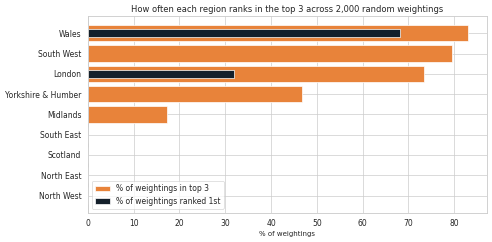

In [9]:
rng = np.random.default_rng(42)
draws = rng.dirichlet(np.ones(3), 2000)             # 2,000 random sets of three weights that add to 1
sim = pd.DataFrame(norm.values @ draws.T, index=norm.index)
sim_rank = sim.rank(ascending=False)

stability = pd.DataFrame({
    'default_rank'    : loc['rank'],
    'pct_rank_1'      : (sim_rank == 1).mean(axis=1) * 100,
    'pct_top_3'       : (sim_rank <= 3).mean(axis=1) * 100,
    'median_rank'     : sim_rank.median(axis=1),
    'best_rank_5pct'  : sim_rank.quantile(0.05, axis=1),
    'worst_rank_95pct': sim_rank.quantile(0.95, axis=1)}).sort_values('pct_top_3', ascending=False)
display(stability.round(1))

for k in WEIGHTS:
    print(f"{k} only, top 3:", norm[k].sort_values(ascending=False).index[:3].tolist())

fig, ax = plt.subplots(figsize=(10, 5))
st = stability.sort_values('pct_top_3')
ax.barh(st.index, st['pct_top_3'], color='#e8833a', label='% of weightings in top 3')
ax.barh(st.index, st['pct_rank_1'], color='#14202b', height=0.4, label='% of weightings ranked 1st')
ax.set_title('How often each region ranks in the top 3 across 2,000 random weightings')
ax.set_xlabel('% of weightings'); ax.legend()
show('05_ranking_stability')

Three regions form the shortlist. Wales is in the top three in 83% of weightings (and first in 68%), South West in 80% (never first, but 2nd to 4th in 90% of weightings) and London in 73% (first in 32%). Yorkshire & Humber reaches the top three in 47% and Midlands in 17%. The North East, South East, Scotland, and the North West never reach the top three.  
The order within the shortlist depends on the weights. Wales and London can each fall to 6th when the weights lean against them, while South West is the most stable. On single criteria, the supply gap alone ranks London, Midlands and South West highest, load per kW alone ranks Wales, London and South West, and customer reach alone ranks Wales, Yorkshire & Humber and Scotland.  
The conclusion is a shortlist of London, the South West, and Wales, with a weak case for the North West and Scotland, not a precise ranking.

**Map of location scores**  
The dataset has no coordinates, so each region is placed at an approximate centre typed in by hand (these are not from the data). The first map is drawn with matplotlib, with bubble size showing the number of stations and colour showing the location score. A second, interactive map is saved as an HTML file.

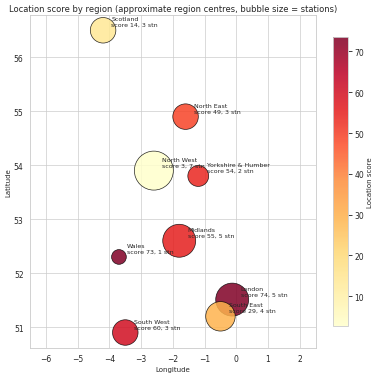

Saved interactive map


In [10]:
CENTRES = {'London': (51.51, -0.13), 'Midlands': (52.60, -1.80), 'North East': (54.90, -1.60),
           'North West': (53.90, -2.60), 'Scotland': (56.50, -4.20), 'South East': (51.20, -0.50),
           'South West': (50.90, -3.50), 'Wales': (52.30, -3.70), 'Yorkshire & Humber': (53.80, -1.20)}
loc['lat'] = [CENTRES[r][0] for r in loc.index]
loc['lon'] = [CENTRES[r][1] for r in loc.index]

fig, ax = plt.subplots(figsize=(8, 10))
sc = ax.scatter(loc['lon'], loc['lat'], s=loc['stations'] * 450, c=loc['score'], cmap='YlOrRd', edgecolor='black', alpha=0.85)
for r, row in loc.iterrows():
    ax.annotate(f"{r}\nscore {row['score']:.0f}, {int(row['stations'])} stn", (row['lon'], row['lat']),
                xytext=(12, 6), textcoords='offset points', fontsize=9)
plt.colorbar(sc, ax=ax, shrink=0.6, label='Location score')
ax.set_aspect(1 / np.cos(np.radians(54)))
ax.set_title('Location score by region (approximate region centres, bubble size = stations)')
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.set_xlim(-6.5, 2.5)
show('06_region_map')

try:
    import folium
    m = folium.Map(location=[53.5, -2.5], zoom_start=6, tiles='cartodbpositron')
    for r, row in loc.iterrows():
        folium.CircleMarker([row['lat'], row['lon']], radius=6 + row['stations'] * 3, color='black', weight=1,
                            fill=True, fill_color='#e8833a' if row['rank'] <= 3 else '#8a949c', fill_opacity=0.8,
                            tooltip=f"{r}: score {row['score']:.0f}, rank {row['rank']}, {int(row['stations'])} stations").add_to(m)
    m.save(f'{OUT}/region_map.html')
    print('Saved interactive map')
except ImportError:
    print('folium is not installed, so the interactive map was skipped')

The map places the strongest cases (London, South West and Wales) in the south and west, and the weakest (North West and Scotland) in the north. Bubble size shows how few stations each region has: Wales has one station, and the North West has seven. The positions are approximate region centres, not real station sites. The interactive map (region_map.html) colours the three highest-ranked regions orange and shows the score, rank and station count when you hover over a region.

**What would a new station earn?**  
Three checks show what can be expected of a new station. First, whether stations opened in 2024 needed time to build demand. Second, whether older stations lost sessions when new ones opened in the same region. Third, how revenue depends on the charger mix. Illustrative earnings are then worked out for four station designs, assuming a new station earns the typical sessions of a day, with sessions spread across chargers in proportion to their number (checked against the actual split).

In [11]:
new_ids = stations.loc[stations['activation_year'] == 2024, 'station_id']
s['month'] = s['start_timestamp'].dt.month
days = pd.Series({m: pd.Period(f'2024-{m:02d}').days_in_month for m in range(1, 13)})
ramp = s[s['station_id'].isin(new_ids) & (s['year'] == 2024)].groupby('month').size() / (len(new_ids) * days)
print(f"Stations opened in 2024: {len(new_ids)} | sessions per station per day by month (min / max): {ramp.min():.1f} / {ramp.max():.1f}")

year_days = pd.Series({2022: 365, 2023: 365, 2024: 366})
old_ids = stations.loc[stations['activation_year'] == 2022, 'station_id']
old_by_year = s[s['station_id'].isin(old_ids)].groupby('year').size() / (len(old_ids) * year_days)
print(f"Stations opened in 2022 ({len(old_ids)}), sessions per day in 2022 / 2023 / 2024:", old_by_year.round(2).tolist())

nw_old = stations.loc[(stations['activation_year'] == 2022) & (stations['region'] == 'North West'), 'station_id']
nw = s[s['station_id'].isin(nw_old)].groupby('year').size() / (len(nw_old) * year_days)
nw_n = [stations[(stations['region'] == 'North West') & (stations['activation_year'] <= y)].shape[0] for y in [2022, 2023, 2024]]
print(f"North West stations in 2022 / 2023 / 2024: {nw_n} | sessions per day at its {len(nw_old)} original stations:", nw.round(2).tolist())

by_type = s24.groupby('charger_type').agg(sessions=('session_id', 'size'), revenue_per_session=('total_cost', 'mean'),
                                          kwh_per_session=('energy_kwh', 'mean'))
by_type['share_of_sessions'] = by_type['sessions'] / by_type['sessions'].sum() * 100
by_type['share_of_chargers'] = chargers['charger_type'].value_counts(normalize=True).reindex(by_type.index) * 100
display(by_type.round(1))

sess_day = len(s24) / (len(stations) * 366)
mix = chargers['charger_type'].value_counts(normalize=True)
ticket, kwh = by_type['revenue_per_session'], by_type['kwh_per_session']
designs = {'All 50 kW chargers': {'DC_50kW': 1.0}, 'All 150 kW chargers': {'DC_150kW': 1.0},
           'All 300 kW chargers': {'DC_300kW': 1.0}, 'Network-average mix': mix.to_dict()}
rows = []
for name, shares in designs.items():
    sh = pd.Series(shares)
    rows.append({'design': name, 'sessions_per_day': sess_day,
                 'revenue_per_day': sess_day * (sh * ticket.reindex(sh.index)).sum(),
                 'kwh_per_day': sess_day * (sh * kwh.reindex(sh.index)).sum()})
econ = pd.DataFrame(rows).set_index('design')
econ['revenue_per_year'] = econ['revenue_per_day'] * 365
display(econ.round(2))

# check: does the mix-based estimate match each station's actual 2024 revenue per day?
st_mix = chargers.groupby(['station_id', 'charger_type']).size().unstack().fillna(0)
st_mix = st_mix.div(st_mix.sum(axis=1), axis=0)
pred = sess_day * (st_mix * ticket.reindex(st_mix.columns)).sum(axis=1)
actual = s24.groupby('station_id')['total_cost'].sum() / 366
print('Estimate vs actual revenue per station-day: correlation', round(pred.corr(actual), 2),
      '| mean absolute error', round((pred - actual).abs().mean(), 0), '| actual mean', round(actual.mean(), 0))

Stations opened in 2024: 16 | sessions per station per day by month (min / max): 13.5 / 14.1
Stations opened in 2022 (8), sessions per day in 2022 / 2023 / 2024: [13.92, 13.83, 13.81]
North West stations in 2022 / 2023 / 2024: [3, 3, 7] | sessions per day at its 3 original stations: [13.74, 13.88, 13.84]


,sessions,revenue_per_session,kwh_per_session,share_of_sessions,share_of_chargers
charger_type,,,,,
DC_150kW,55549,28.8,49.0,33.2,34.7
DC_300kW,31636,44.4,75.5,18.9,17.6
DC_50kW,80067,19.4,33.0,47.9,47.7


,sessions_per_day,revenue_per_day,kwh_per_day,revenue_per_year
design,,,,
All 50 kW chargers,13.85,268.33,456.40,97941.31
All 150 kW chargers,13.85,398.72,678.02,145533.15
All 300 kW chargers,13.85,614.39,1045.75,224251.75
Network-average mix,13.85,374.41,636.89,136658.41


Estimate vs actual revenue per station-day: correlation 1.0 | mean absolute error 4.0 | actual mean 377.0


New stations do not need a ramp-up. The 16 stations opened in 2024 earned between 13.5 and 14.1 sessions a day in every month, from the first month. Older stations do not lose sessions when new ones open: the 8 stations opened in 2022 earned 13.92, 13.83 and 13.81 sessions a day in 2022, 2023 and 2024, and North West's 3 original stations stayed at about 13.8 a day (13.74, 13.88, 13.84) when the region went from 3 to 7 stations.  
Revenue depends on the charger mix, not the region. A session earns 19.4 on a 50 kW charger, 28.8 on 150 kW and 44.4 on 300 kW (delivering 33, 49 and 75.5 kWh). Sessions are spread across chargers in proportion to their number (50 kW chargers are 47.7% of chargers and take 47.9% of sessions), so the mix alone predicts each station's revenue: the estimate matches actual 2024 revenue per station-day almost perfectly (correlation 1.00, mean error 4 a day).  
At the typical 13.85 sessions a day, an all-50 kW station would earn about 268 a day (97,900 a year), an all-150 kW station 399 (145,500), an all-300 kW station 614 (224,300) and a station with the network-average mix 374 (136,700), against an actual network average of 377. These are revenue in the dataset's price units, not profit. The data doesn't include build and running costs, and 300 kW chargers cost much more to install than 50 kW ones.

**Expansion strategy**  
The recommendations are limited to what the evidence supports. The data supports a shortlist of regions, not site choices.
1. **Shortlist London, South West and Wales.** They are in the top three in 73% to 83% of 2,000 random weightings, each for a different reason. London has the largest supply gap (15.3% of demand against 12.6% of chargers) and the highest utilisation (7.1%). South West has a positive gap (+1.5 points) and the steadiest ranking (2nd to 4th in 90% of weightings). Wales has one station with 8 slow chargers, the highest load per kW (1.14) and customer reach, but the evidence is a single site.
2. **Build faster chargers where a region has only slow ones.** Wales's station earns 267 a day against an estimated 399 for a 150 kW station, because all its chargers are 50 kW. The charger mix affects revenue much more than the region does.
3. **Do not expand in North West or Scotland.** They have more supply than their demand share (gaps of -2.9 and -2.0 points), the lowest scores (2.7 and 14.0) and never reach the top three. North East and South East do not reach it either.
4. **Plan on typical performance.** Every station opened in 2022 to 2024 earned about 13.85 sessions a day from its first month, and older stations lost nothing when new ones opened nearby. A typical new station can be planned at about 374 revenue a day (about 137,000 a year) at the network-average mix. The data cannot say whether any region will do better than another.
5. **Keep new stations small and treat them as coverage, not capacity.** Utilisation is 5.4% across the network and no region is above 7.1%, so no region is short of capacity. The earlier charger utilisation analysis found that almost every station needs only about 3 chargers at the 99.9% standard.
6. **Get site-level data before choosing sites.** Coordinates, EV registrations or population, traffic flows, grid capacity, competitor chargers and build costs are all missing. Use them to rank specific sites inside the three shortlisted regions.
7. **Open in stages and measure.** Start with one or two stations in the top regions and compare their first 6 to 12 months with the 13.85 sessions-a-day benchmark before committing to more.

**Saving the outputs**  
The regional tables, score, ranking stability, demand heatmap data, and new-station estimates are saved as CSVs so they can be used in the dashboard.

In [12]:
yearly = pd.concat([yr.stack().rename('sessions'), per_station_day.stack().rename('sessions_per_station_day')], axis=1).reset_index()
yearly.columns = ['region', 'year', 'sessions', 'sessions_per_station_day']
hourly = hour_share.stack().reset_index()
hourly.columns = ['region', 'hour', 'share_pct']

files = {
    'regional_supply_demand.csv': reg.drop(columns='busy_min').reset_index(),
    'gap_analysis.csv'          : gap.reset_index(),
    'customer_reach.csv'        : reach.reset_index(),
    'location_scores.csv'       : loc.reset_index(),
    'ranking_stability.csv'     : stability.reset_index(),
    'regional_yearly_demand.csv': yearly,
    'regional_hourly_demand.csv': hourly,
    'new_station_economics.csv' : econ.reset_index(),
}
for name, df in files.items():
    df.to_csv(f'{OUT}/{name}', index=False)
print(sorted(f for f in os.listdir(OUT) if f.endswith('.csv') or f.endswith('.html')))

['customer_reach.csv', 'gap_analysis.csv', 'location_scores.csv', 'new_station_economics.csv', 'ranking_stability.csv', 'region_map.html', 'regional_hourly_demand.csv', 'regional_supply_demand.csv', 'regional_yearly_demand.csv']


Eight CSVs are saved to /kaggle/working, together with the interactive map (region_map.html), and the charts are saved as PNGs in the figures folder. Each table has one row per region, except from the yearly demand (region and year), hourly demand (region and hour), and new-station estimates (one row per station design).